# Climate change in six Italian cities

This notebook investigates daily Open-Meteo ERA5 data for Milan, Turin, Rome, Bari, Palermo and Cagliari from 1940 to 2025.

Research questions:

1. How has annual mean temperature changed?
2. Which cities have the largest descriptive warming trends?
3. Have hot days and tropical nights become more frequent?
4. How have annual precipitation patterns changed?
5. How do recent seasonal temperatures compare with the historical period?


## 1. Project setup

The notebook imports reusable calculations and plotting functions from the `scripts` folder. The analysis logic is therefore tested separately and is not duplicated in notebook cells.


In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from scripts.analysis import (
    add_calendar_features,
    calculate_annual_summary,
    calculate_seasonal_comparison,
    calculate_temperature_anomalies,
    calculate_temperature_trends,
    compare_climate_periods,
)
from scripts.plots import (
    configure_plot_style,
    plot_annual_temperature,
    plot_hot_days,
    plot_precipitation,
    plot_seasonal_comparison,
    plot_temperature_anomalies,
    plot_temperature_trends,
    save_figure,
)

pd.set_option("display.max_columns", None)
configure_plot_style()


## 2. Load the cleaned daily data

Notebook 02 creates the processed CSV after checking dates, duplicates, missing values, temperature order and precipitation quality. This notebook stops with a clear error if that file is absent.


In [3]:
DATA_FILE = PROJECT_ROOT / "data" / "processed" / "weather_daily_1940_2025.csv"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "eda"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"

if not DATA_FILE.exists():
    raise FileNotFoundError("Run notebooks 01 and 02 before this analysis notebook.")

weather = pd.read_csv(DATA_FILE, parse_dates=["date"])
print(f"Rows: {len(weather):,}")
print(f"Cities: {weather['city'].nunique()}")
print(f"Period: {weather['date'].min().date()} to {weather['date'].max().date()}")
weather.head()


Rows: 188,472
Cities: 6
Period: 1940-01-01 to 2025-12-31


,city,city_slug,requested_latitude,requested_longitude,grid_latitude,grid_longitude,grid_elevation,date,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum
0,Bari,bari,41.1171,16.8719,41.0,16.75,9.0,1940-01-01,1.6,3.9,-1.6,NaN
1,Bari,bari,41.1171,16.8719,41.0,16.75,9.0,1940-01-02,2.6,4.9,1.2,1.3
2,Bari,bari,41.1171,16.8719,41.0,16.75,9.0,1940-01-03,1.5,4.4,-0.6,0.0
3,Bari,bari,41.1171,16.8719,41.0,16.75,9.0,1940-01-04,6.6,9.0,2.3,7.6
4,Bari,bari,41.1171,16.8719,41.0,16.75,9.0,1940-01-05,9.4,12.0,7.5,11.1


In [4]:
coverage = (
    weather.groupby("city")
    .agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        rows=("date", "size"),
        missing_precipitation=("precipitation_sum", "count"),
    )
)
coverage["missing_precipitation"] = coverage["rows"] - coverage["missing_precipitation"]
coverage


,first_date,last_date,rows,missing_precipitation
city,,,,
Bari,1940-01-01,2025-12-31,31412,1
Cagliari,1940-01-01,2025-12-31,31412,1
Milan,1940-01-01,2025-12-31,31412,1
Palermo,1940-01-01,2025-12-31,31412,1
Rome,1940-01-01,2025-12-31,31412,1
Turin,1940-01-01,2025-12-31,31412,1


Each city must cover the same period. Open-Meteo contains one missing precipitation value per city on 1 January 1940. These values remain missing and are never replaced with zero.


## 3. Prepare the analysis tables

Calendar columns support annual and meteorological-season aggregation. The annual summary uses three clearly defined event thresholds:

- hot day: maximum temperature ≥ 30 °C;
- tropical night: minimum temperature ≥ 20 °C;
- heavy-rain day: precipitation ≥ 20 mm.


In [5]:
weather = add_calendar_features(weather)
annual_summary = calculate_annual_summary(weather, rolling_window=10)
annual_summary = calculate_temperature_anomalies(
    annual_summary,
    baseline_start=1961,
    baseline_end=1990,
)
temperature_trends = calculate_temperature_trends(annual_summary)
seasonal_comparison = calculate_seasonal_comparison(weather)

comparison_metrics = [
    "temperature_mean",
    "hot_days",
    "tropical_nights",
    "precipitation_total",
    "heavy_rain_days",
]
period_comparison = compare_climate_periods(
    annual_summary,
    metrics=comparison_metrics,
)


## 4. Descriptive statistics

Mean and median describe the center of each city's daily temperature distribution. Standard deviation describes its variability; minimum and maximum show the observed range.


In [6]:
descriptive_statistics = (
    weather.groupby("city")["temperature_2m_mean"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)
descriptive_statistics


,count,mean,median,std,min,max
city,,,,,,
Bari,31412,17.35,16.8,6.74,-1.9,37.4
Cagliari,31412,17.50,16.8,5.89,2.1,33.9
Milan,31412,13.09,13.3,8.07,-12.1,32.1
Palermo,31412,18.54,17.9,6.32,1.9,36.9
Rome,31412,15.76,15.4,6.93,-7.4,32.5
Turin,31412,12.82,13.0,8.06,-13.2,32.7


## 5. Annual mean temperature

Thin lines show individual years. The trailing 10-year mean reduces short-term variability and makes the long-term direction easier to see.


Weather-Report/reports/figures/eda/01_annual_temperature.png


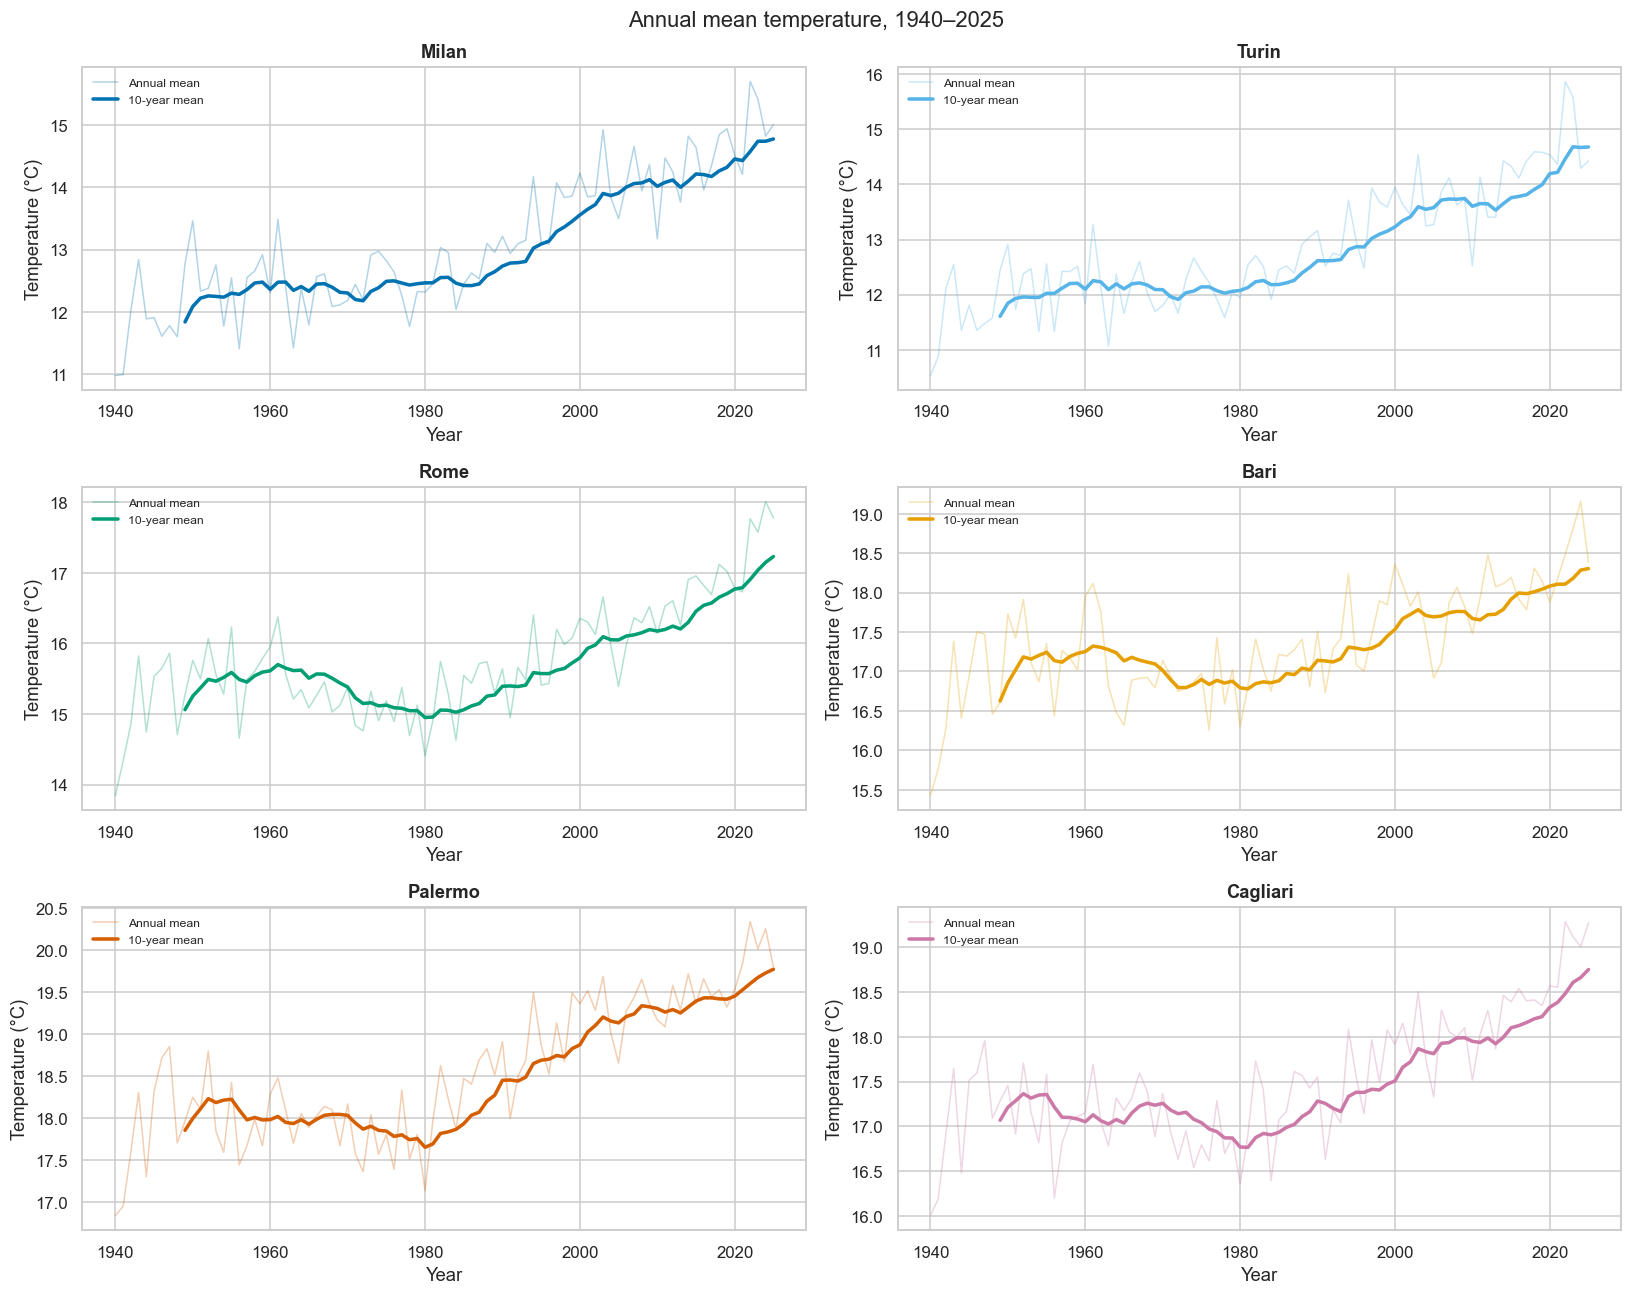

In [7]:
figure = plot_annual_temperature(annual_summary)
figure_path = save_figure(figure, FIGURE_DIR, "01_annual_temperature.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
plt.show()
plt.close(figure)


## 6. Temperature anomalies

An anomaly is the difference between an annual temperature and that city's 1961–1990 average. Red bars are warmer than the baseline; blue bars are colder. Using a city-specific baseline makes changes comparable without confusing them with normal geographic differences.


Weather-Report/reports/figures/eda/02_temperature_anomalies.png


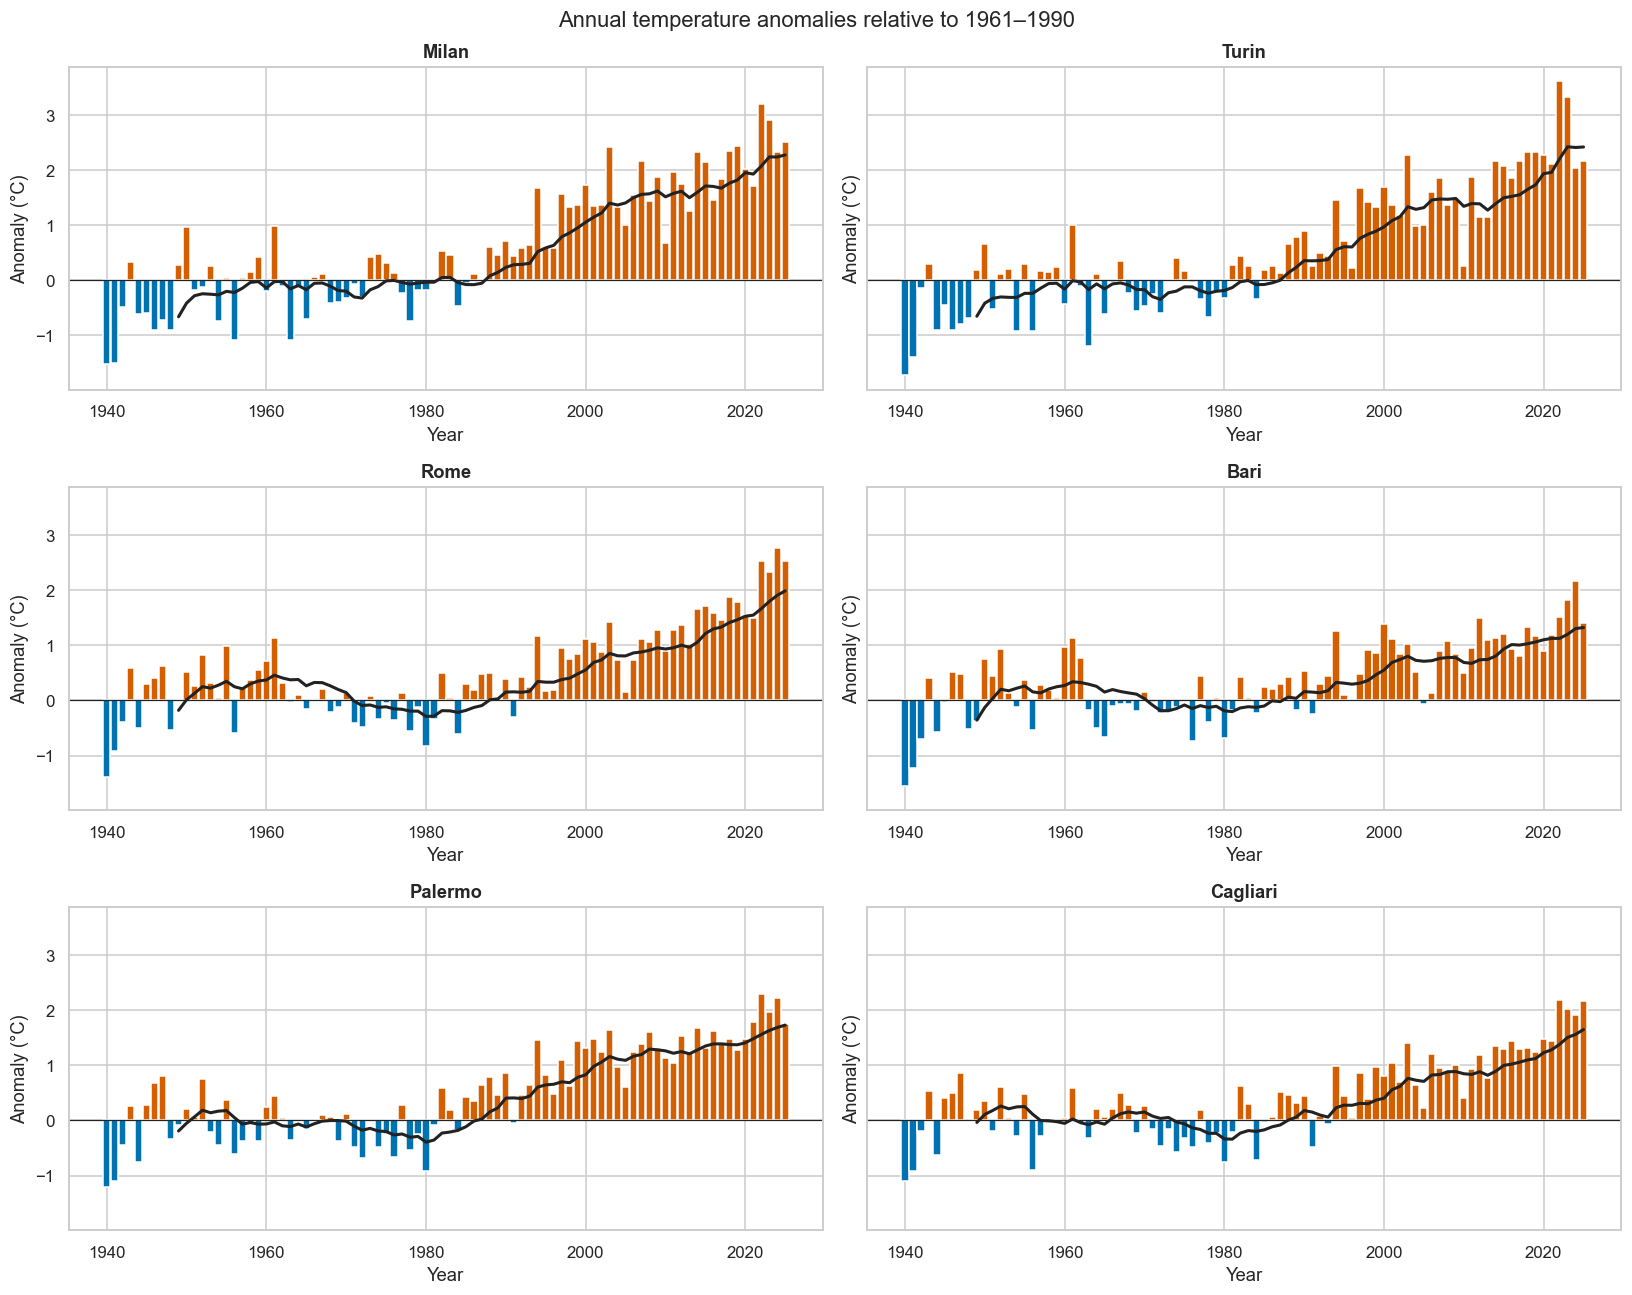

In [8]:
figure = plot_temperature_anomalies(annual_summary)
figure_path = save_figure(figure, FIGURE_DIR, "02_temperature_anomalies.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
plt.show()
plt.close(figure)


## 7. Descriptive temperature trends

`numpy.polyfit()` fits one straight line to each city's annual averages. The slope is multiplied by ten and reported in °C per decade.

This is a descriptive summary, not a hypothesis test. It does not provide a p-value or establish statistical significance or causation.


,city,city_slug,start_year,end_year,slope_celsius_per_decade
0,Milan,milan,1940,2025,0.370
1,Turin,turin,1940,2025,0.369
2,Palermo,palermo,1940,2025,0.267
3,Rome,rome,1940,2025,0.234
4,Cagliari,cagliari,1940,2025,0.206
5,Bari,bari,1940,2025,0.186


Weather-Report/reports/figures/eda/03_temperature_trends.png


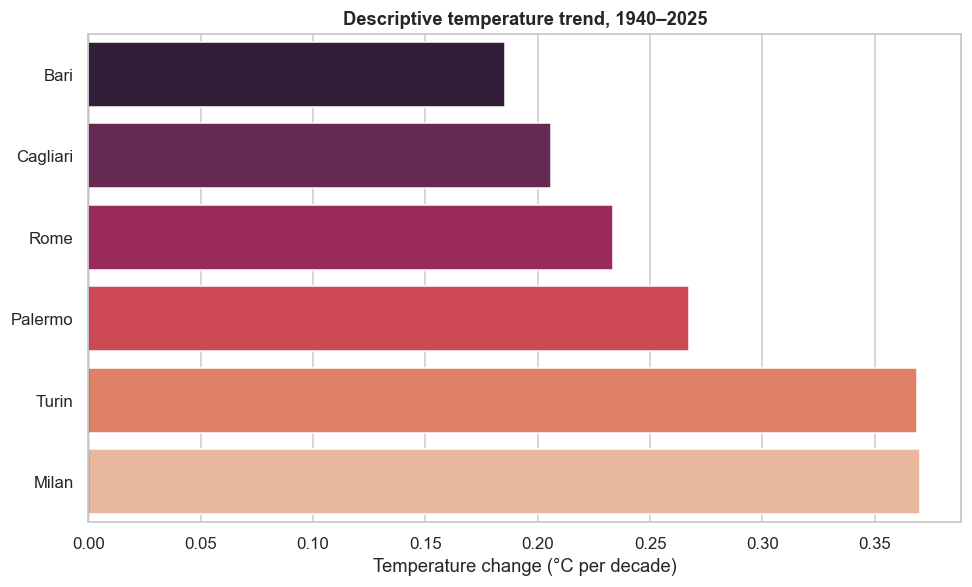

In [9]:
display(temperature_trends.round({"slope_celsius_per_decade": 3}))

figure = plot_temperature_trends(temperature_trends)
figure_path = save_figure(figure, FIGURE_DIR, "03_temperature_trends.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
plt.show()
plt.close(figure)


## 8. Hot days and tropical nights

The chart uses trailing 10-year averages because annual event counts can vary considerably. Fixed thresholds are simple, transparent and reproducible, although they do not account for differences in the normal climate of each city.


,city,metric,early_mean,recent_mean,absolute_change
1,Bari,hot_days,57.0,66.8,9.7
2,Bari,tropical_nights,67.9,85.4,17.5
6,Cagliari,hot_days,36.2,58.0,21.8
7,Cagliari,tropical_nights,58.9,79.8,21.0
11,Milan,hot_days,15.6,42.5,26.9
12,Milan,tropical_nights,10.1,42.1,32.0
16,Palermo,hot_days,65.1,78.1,13.0
17,Palermo,tropical_nights,75.9,108.2,32.3
21,Rome,hot_days,46.0,65.7,19.6
22,Rome,tropical_nights,24.6,47.8,23.3


Weather-Report/reports/figures/eda/04_hot_days.png


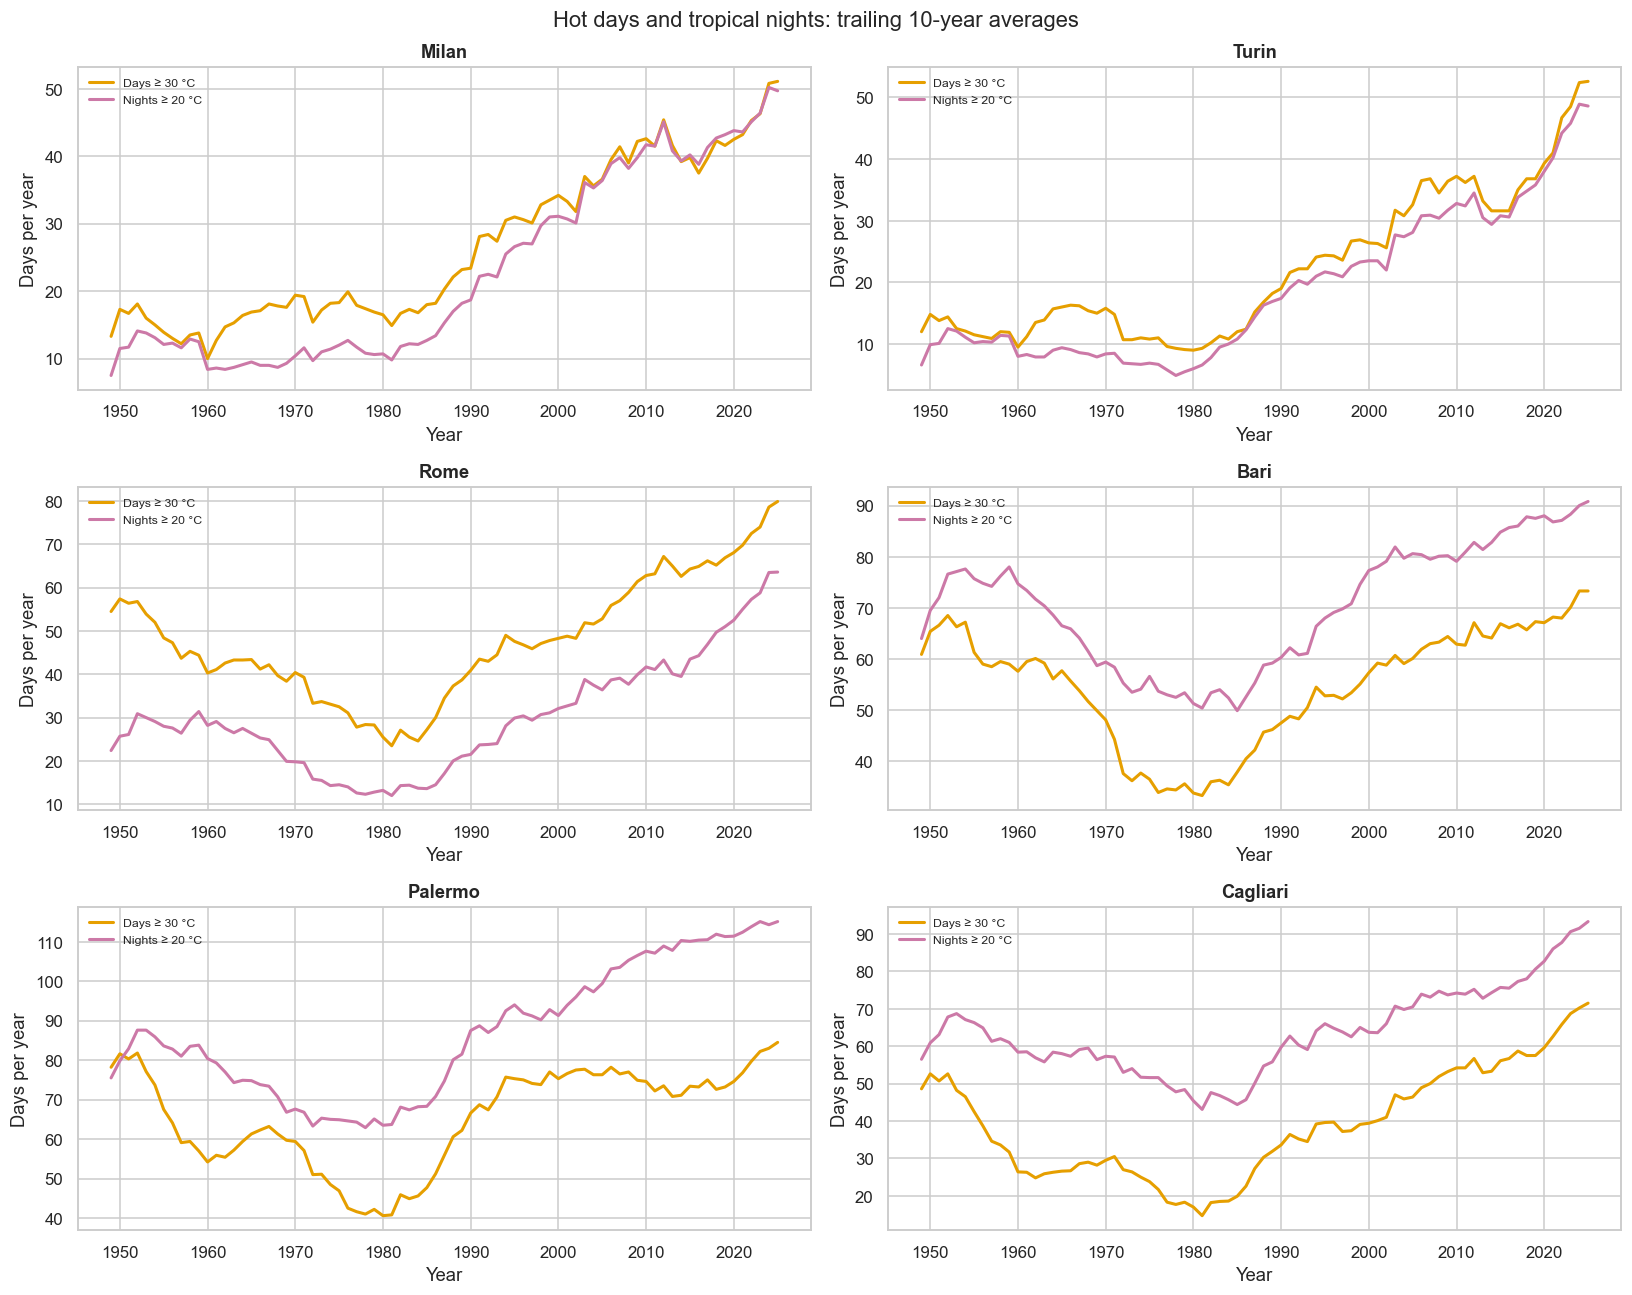

In [10]:
heat_comparison = period_comparison.loc[
    period_comparison["metric"].isin(["hot_days", "tropical_nights"]),
    ["city", "metric", "early_mean", "recent_mean", "absolute_change"],
]
display(heat_comparison.round(1))

figure = plot_hot_days(annual_summary)
figure_path = save_figure(figure, FIGURE_DIR, "04_hot_days.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
plt.show()
plt.close(figure)


## 9. Annual precipitation

Precipitation is more variable than temperature. The chart shows annual totals and a trailing 10-year mean. The incomplete precipitation year 1940 remains missing and is not included as a valid annual total.


,city,year,precipitation_missing_days
0,Bari,1940,1
86,Cagliari,1940,1
172,Milan,1940,1
258,Palermo,1940,1
344,Rome,1940,1
430,Turin,1940,1


Weather-Report/reports/figures/eda/05_annual_precipitation.png


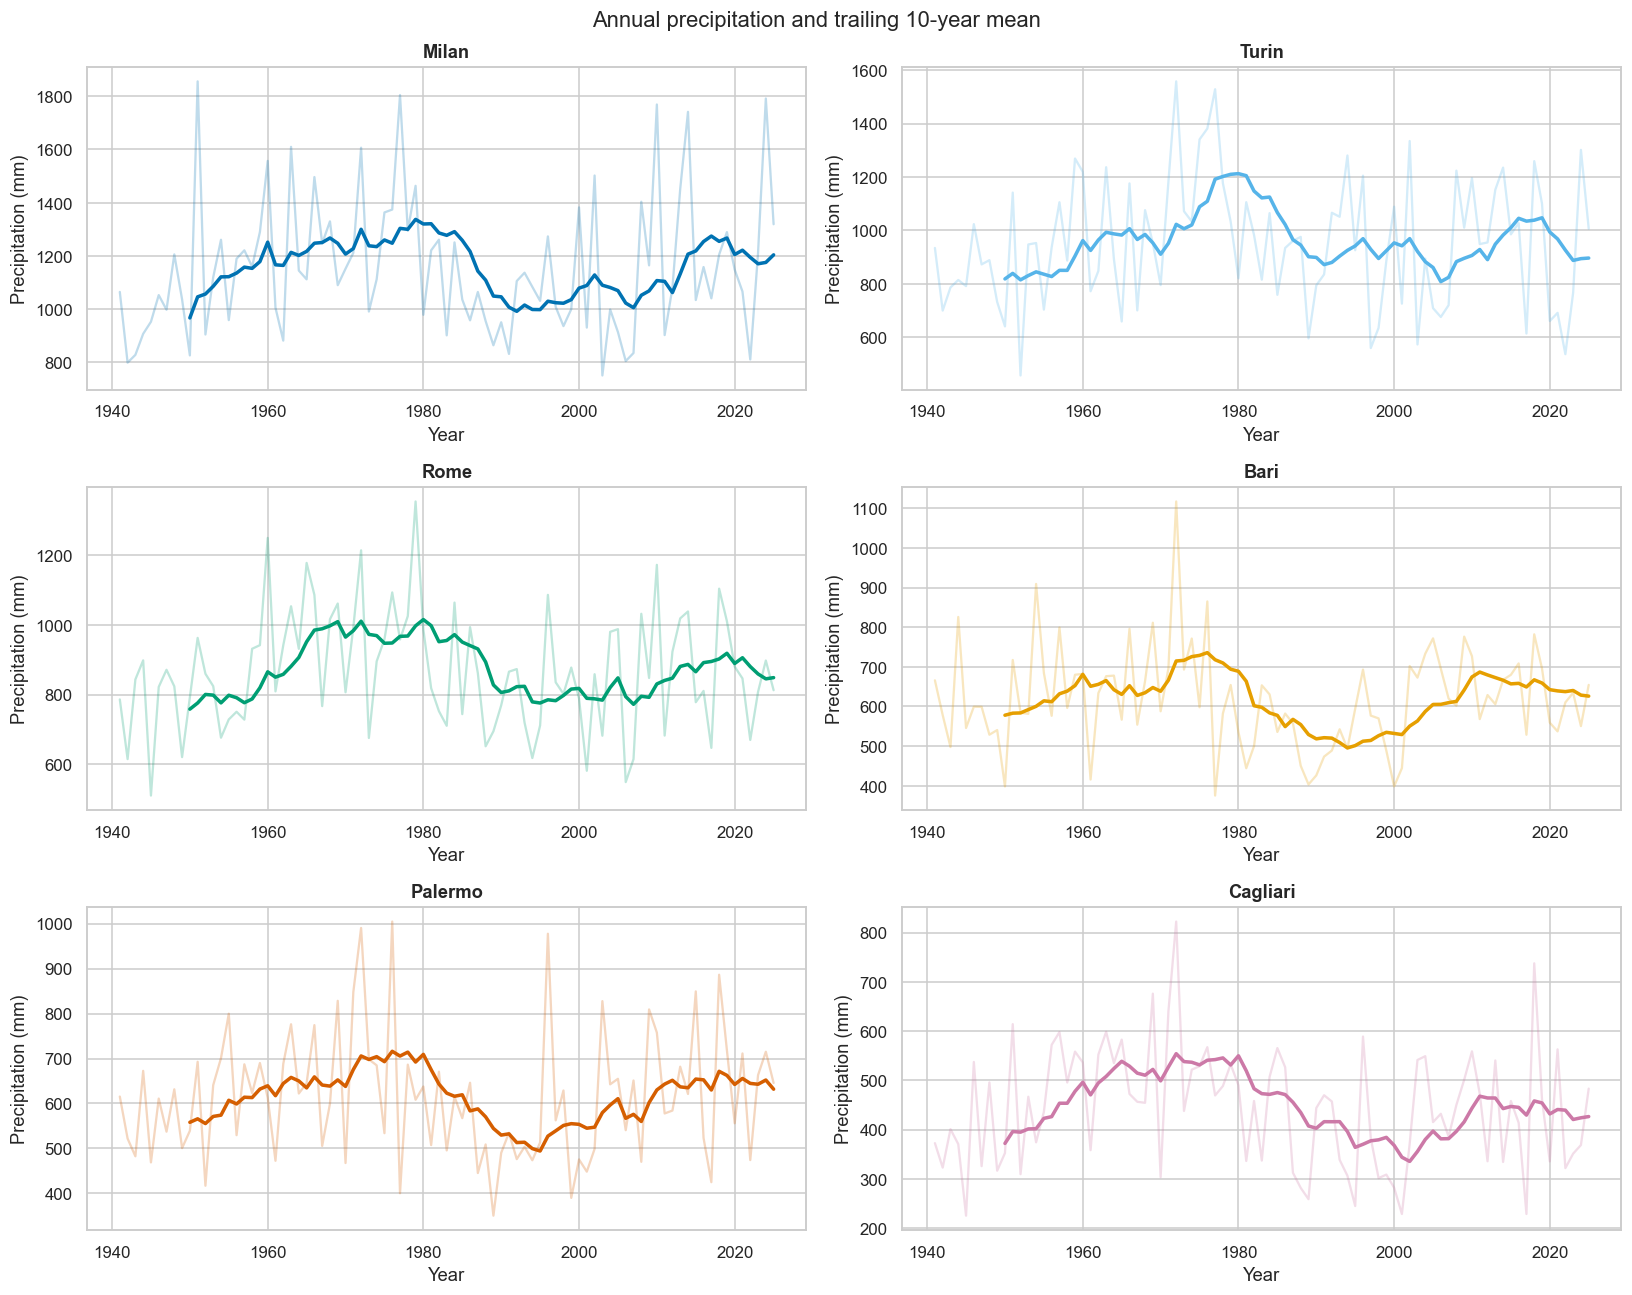

In [11]:
missing_rain_years = annual_summary.loc[
    annual_summary["precipitation_total"].isna(),
    ["city", "year", "precipitation_missing_days"],
]
display(missing_rain_years)

figure = plot_precipitation(annual_summary)
figure_path = save_figure(figure, FIGURE_DIR, "05_annual_precipitation.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
plt.show()
plt.close(figure)


## 10. Seasonal temperature comparison

Meteorological seasons are winter (December–February), spring (March–May), summer (June–August) and autumn (September–November). December is assigned to the following winter year. Incomplete boundary seasons are excluded.

The chart compares two complete 30-year periods: 1941–1970 and 1996–2025.


period,city,season,1941–1970,1996–2025,change
0,Bari,Autumn,18.15,18.80,0.65
1,Bari,Spring,15.12,16.01,0.89
2,Bari,Summer,25.29,26.51,1.22
3,Bari,Winter,9.39,10.44,1.05
4,Cagliari,Autumn,18.68,19.62,0.94
5,Cagliari,Spring,14.95,15.88,0.93
6,Cagliari,Summer,24.31,25.71,1.39
7,Cagliari,Winter,10.58,11.56,0.98
8,Milan,Autumn,12.91,14.24,1.33
9,Milan,Spring,12.27,14.10,1.83


Weather-Report/reports/figures/eda/06_seasonal_comparison.png


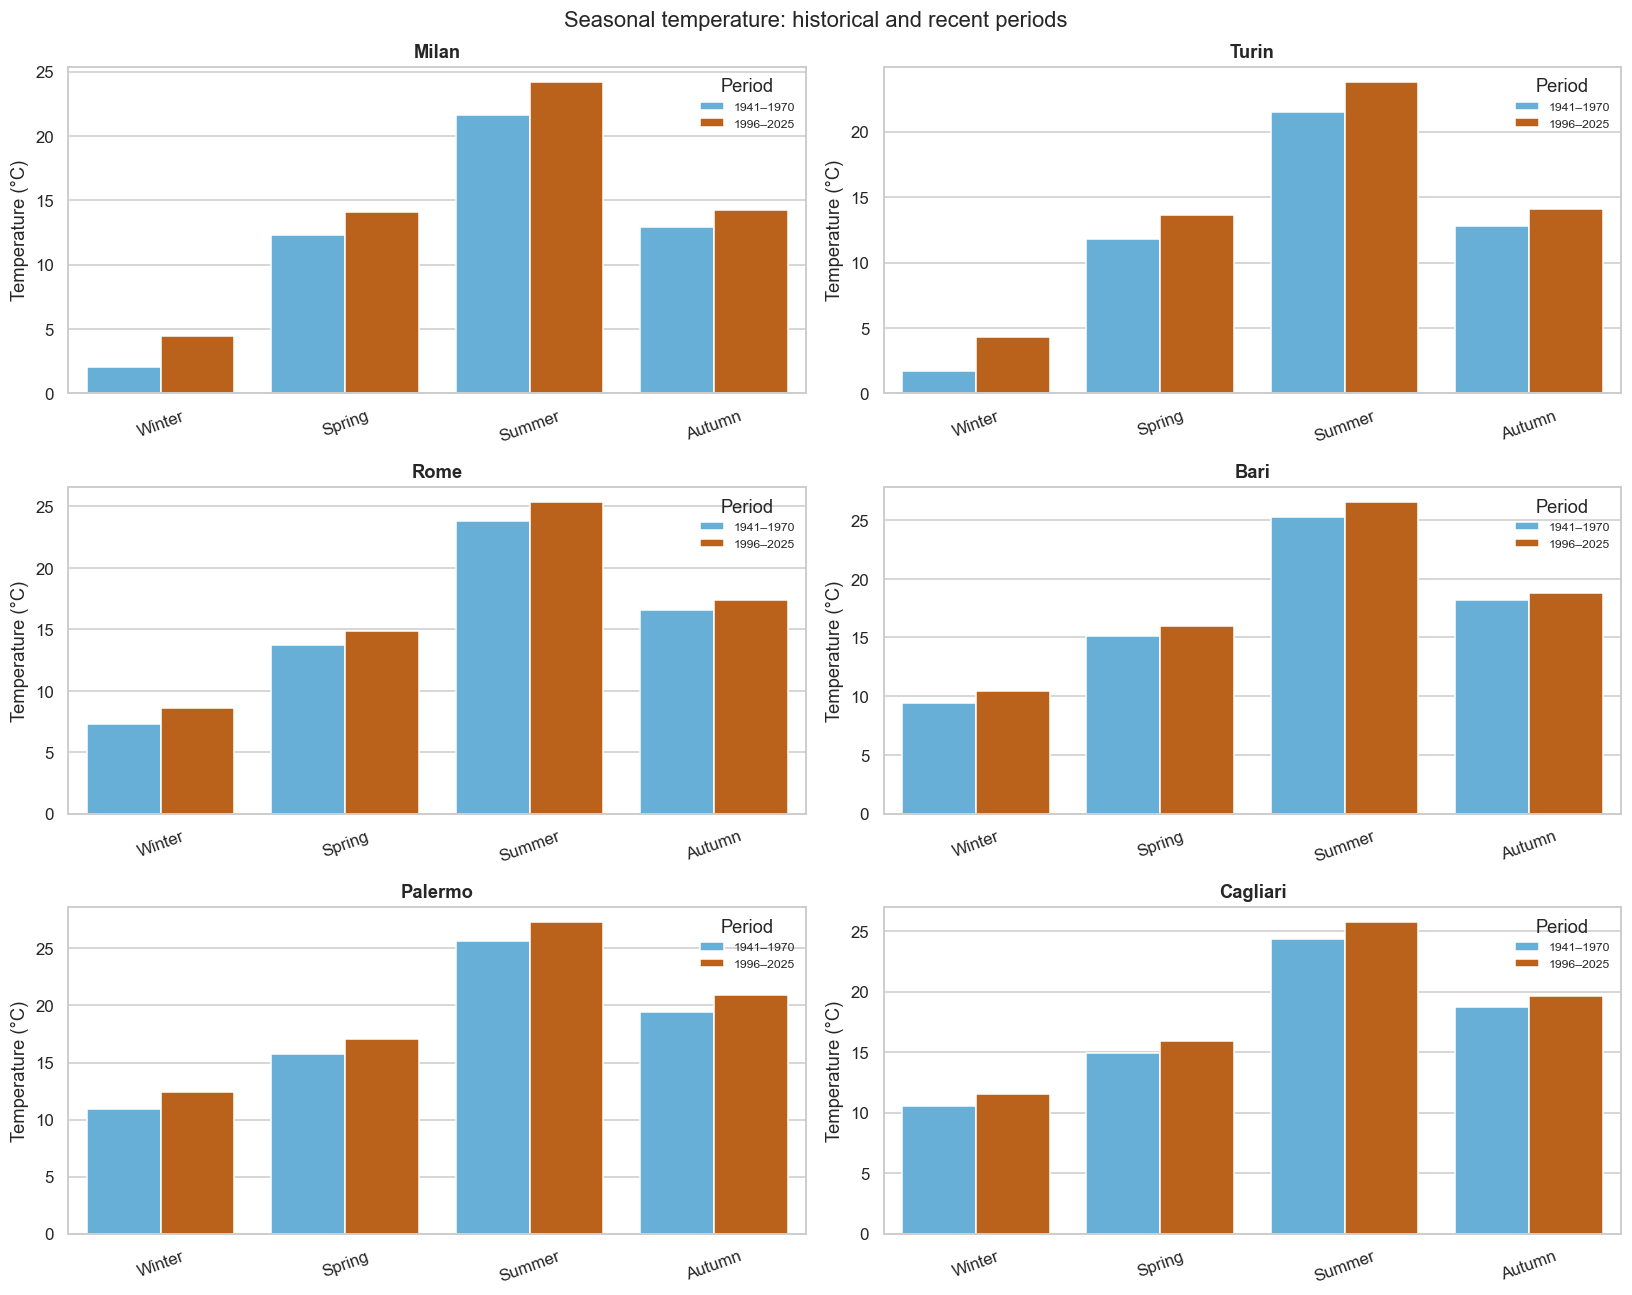

In [12]:
seasonal_table = seasonal_comparison.pivot_table(
    index=["city", "season"],
    columns="period",
    values="temperature_mean",
).reset_index()
seasonal_table["change"] = seasonal_table["1996–2025"] - seasonal_table["1941–1970"]
display(seasonal_table.round(2))

figure = plot_seasonal_comparison(seasonal_comparison)
figure_path = save_figure(figure, FIGURE_DIR, "06_seasonal_comparison.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
plt.show()
plt.close(figure)


## 11. Historical and recent periods

The same periods are compared for all main indicators. `absolute_change` is the recent mean minus the historical mean. This comparison is easy to interpret and does not require inferential statistics.


In [13]:
display(
    period_comparison.sort_values(["metric", "absolute_change"], ascending=[True, False])
    .round(2)
)


,city,city_slug,metric,early_period,recent_period,early_mean,recent_mean,absolute_change
14,Milan,milan,heavy_rain_days,1941–1970,1996–2025,15.63,17.73,2.10
19,Palermo,palermo,heavy_rain_days,1941–1970,1996–2025,3.07,4.17,1.10
24,Rome,rome,heavy_rain_days,1941–1970,1996–2025,7.67,8.67,1.00
29,Turin,turin,heavy_rain_days,1941–1970,1996–2025,10.43,11.07,0.63
4,Bari,bari,heavy_rain_days,1941–1970,1996–2025,4.27,4.73,0.47
9,Cagliari,cagliari,heavy_rain_days,1941–1970,1996–2025,2.90,2.63,-0.27
11,Milan,milan,hot_days,1941–1970,1996–2025,15.57,42.50,26.93
26,Turin,turin,hot_days,1941–1970,1996–2025,13.37,38.93,25.57
6,Cagliari,cagliari,hot_days,1941–1970,1996–2025,36.17,58.00,21.83
21,Rome,rome,hot_days,1941–1970,1996–2025,46.03,65.67,19.63


## 12. Main findings generated from the data

The statements below are produced from the calculated tables, avoiding manually entered numerical results.


In [14]:
print("Descriptive annual temperature trends:")
for row in temperature_trends.itertuples(index=False):
    print(f"- {row.city}: {row.slope_celsius_per_decade:+.2f} °C per decade")

print()
print("Recent minus historical mean temperature:")
temperature_change = period_comparison.loc[
    period_comparison["metric"] == "temperature_mean"
]
for row in temperature_change.itertuples(index=False):
    print(f"- {row.city}: {row.absolute_change:+.2f} °C")

print()
print("These are descriptive patterns in the observed ERA5 data, not causal claims.")


Descriptive annual temperature trends:
- Milan: +0.37 °C per decade
- Turin: +0.37 °C per decade
- Palermo: +0.27 °C per decade
- Rome: +0.23 °C per decade
- Cagliari: +0.21 °C per decade
- Bari: +0.19 °C per decade

Recent minus historical mean temperature:
- Bari: +0.93 °C
- Cagliari: +1.05 °C
- Milan: +2.05 °C
- Palermo: +1.43 °C
- Rome: +1.16 °C
- Turin: +1.99 °C

These are descriptive patterns in the observed ERA5 data, not causal claims.


## 13. Save the main derived tables

Only three compact tables are saved. All other results can be reproduced by running this notebook.


In [15]:
outputs = {
    "annual_climate_summary.csv": annual_summary,
    "seasonal_temperature_comparison.csv": seasonal_comparison,
    "period_comparison.csv": period_comparison,
}

for filename, dataframe in outputs.items():
    output_path = OUTPUT_DIR / filename
    dataframe.to_csv(output_path, index=False)
    print(f"Saved {len(dataframe):,} rows: {Path(PROJECT_ROOT.name) / output_path.relative_to(PROJECT_ROOT)}")


Saved 516 rows: Weather-Report/data/processed/annual_climate_summary.csv
Saved 48 rows: Weather-Report/data/processed/seasonal_temperature_comparison.csv
Saved 30 rows: Weather-Report/data/processed/period_comparison.csv


## 14. Limitations and conclusion

- ERA5 describes a model grid cell around each city, not a single weather station.
- The project cannot separate regional climate change from urban heat-island effects.
- Fixed heat thresholds are easy to explain but represent different levels of rarity in different cities.
- Linear slopes summarize average direction and may hide nonlinear changes.
- No confidence intervals or hypothesis tests are calculated, so the analysis does not claim statistical significance.
- The analysis describes associations over time and does not perform causal attribution.

Within these limits, the annual series, anomalies, fixed-threshold event counts, period comparisons and seasonal summaries provide a clear descriptive answer to the project questions.
